# 03 · Well performance

This notebook quantifies how the system performed, using the cleaned data from notebook 02.

1. Injection side: pressure and injectivity at 10 bpm.
2. Recovery: the fraction of the injected volume that returns as liquid.
3. Steam: the fraction of the produced water that flashes to steam at the separator, calculated from an energy balance.
4. Efficiency: mass flow out divided by mass flow in, the metric the report gives as its headline (about 90%).
5. Uncertainty: how much the results depend on the assumptions made.

The notebook adds `iapws` (steam tables) to the tools used so far.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from load import load_clean, load_flow_calibration, load_constants, load_manual_tp
from clean import temperature_offset
from analysis import (separator_conditions, steam_fraction, mass_flows,
                      injectivity_index, linear_trend, recalibrate_through_origin)
from plots import apply_style, savefig, shade_window

apply_style()

d = load_clean("30s")                       # the cleaned data from notebook 02
steady = d[d["valid_steady"]].copy()        # only rows where injection is steady
print(f"{len(steady):,} steady rows from {steady.index.min()} to {steady.index.max()}")

65,856 steady rows from 2024-08-11 08:05:00 to 2024-09-04 06:00:10


## 1. Measurement period

Notebook 02 flags the injection as steady, but production was still developing. The measurement window is therefore chosen where the efficiency itself stops changing, using the mass-flow calculation described in section 5.

Rule: working backwards from the end of the test, include days while the daily efficiency stays within 2% of the final value. The first day that breaks the rule marks the start of the plateau.

In [2]:
mf = mass_flows(steady)                                   # mass flows for every steady row
daily_eff = mf["efficiency"].groupby(steady.index.date).median()

final = daily_eff.iloc[-3:].median()                      # level at the end of the test
close = ((daily_eff - final).abs() / final) <= 0.02       # True where within 2% of that level

plateau_start = None
for day in reversed(daily_eff.index):                     # walk backwards from the last day
    if close[day]:
        plateau_start = day
    else:
        break

plateau = steady.loc[str(plateau_start):]
print("Final efficiency level :", round(final, 3))
print("Plateau starts         :", plateau_start)
print("Plateau length         :", plateau.index.normalize().nunique(), "days,", f"{len(plateau):,}", "rows")

Final efficiency level : 0.906
Plateau starts         : 2024-08-29
Plateau length         : 7 days, 18,001 rows


`steady.loc["2024-08-29":]` selects all rows from a date to the end of the table.

The headline numbers use this plateau window. The whole steady period is also shown to document how the well evolved.

## 2. Injection pressure and injectivity

Injectivity measures how readily the formation accepts water: more flow per unit of pressure means higher injectivity. Here it is defined as

$$\text{injectivity} = \frac{\text{injection rate (gpm)}}{\text{wellhead pressure (psi)}} \times 100$$

in gpm per 100 psi.

Wellhead pressure includes the weight of the water column and friction in the pipe, not only the pressure at the formation. At a constant rate with similar cold injection water those terms are roughly constant, so the trend is informative but the absolute value is not a reservoir property.

Pressure starts to decline after: 2024-08-21


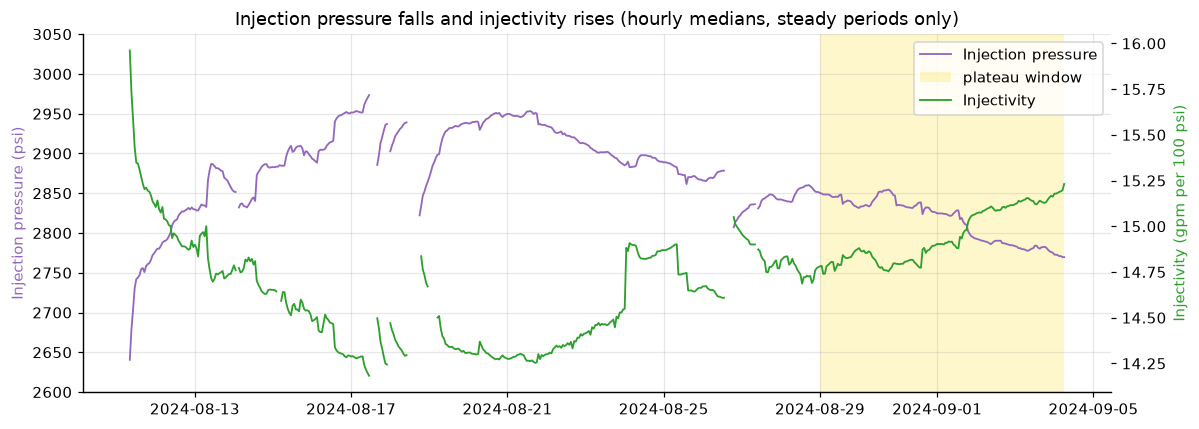

In [3]:
hs = steady.drop(columns=["phase", "valid_steady"]).resample("1h").median()   # hourly medians
hs["injectivity"] = injectivity_index(hs)

daily_p = steady["p_inj_psi"].resample("1D").median().dropna()      # one value per day, on a real date index
# Highest daily pressure AFTER the 17-18 Aug pump stops: where the pressure begins to fall
trend_start = daily_p.loc["2024-08-19":].idxmax().date()
print("Pressure starts to decline after:", trend_start)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hs.index, hs["p_inj_psi"], color="tab:purple", lw=1.2, label="Injection pressure")
ax.set_ylabel("Injection pressure (psi)", color="tab:purple"); ax.set_ylim(2600, 3050)
ax2 = ax.twinx()
ax2.plot(hs.index, hs["injectivity"], color="tab:green", lw=1.2, label="Injectivity")
ax2.set_ylabel("Injectivity (gpm per 100 psi)", color="tab:green"); ax2.grid(False)
shade_window(ax, plateau.index.min(), plateau.index.max(), label="plateau window")
ax.set_title("Injection pressure falls and injectivity rises (hourly medians, steady periods only)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")          # one combined legend for both axes
savefig(fig, "03_pressure_injectivity.png"); plt.show()

`ax.twinx()` adds a second y-axis that shares the time axis. Each axis label is coloured to match its line.

Pressure rises during the first days and then falls. Injectivity moves in the opposite direction, as expected at constant rate.

Injectivity steps up on 24 Aug and back down on 26 Aug. This coincides with a brief increase in pump rate to about 10.2 bpm. Injectivity is rate divided by pressure, so it responds to a rate change immediately while the pressure responds more slowly. The step is therefore more likely a rate effect than a change in the formation, and pressure is the cleaner indicator. The pressure trend is fitted first.

In [4]:
p_trend = linear_trend(hs.loc[str(trend_start):, "p_inj_psi"])
i_trend = linear_trend(hs.loc[str(trend_start):, "injectivity"])
p0 = hs.loc[str(trend_start), "p_inj_psi"].median()

print(f"From {trend_start} to the end ({p_trend['days']:.1f} days):")
print(f"  Injection pressure: {p_trend['slope_per_day']:+.1f} psi/day  (total {p_trend['change']:+.0f} psi, {p_trend['change']/p0*100:+.1f}%)   R² = {p_trend['r2']:.2f}")
print(f"  Injectivity       : {i_trend['slope_per_day']:+.3f} gpm/100psi per day  (total {i_trend['change']:+.2f}, from about {hs.loc[str(trend_start):, 'injectivity'].iloc[:24].mean():.1f})")

From 2024-08-21 to the end (14.2 days):
  Injection pressure: -11.1 psi/day  (total -158 psi, -5.4%)   R² = 0.91
  Injectivity       : +0.053 gpm/100psi per day  (total +0.75, from about 14.3)


The pressure decline agrees with the report, which describes injection pressures as high but starting to decline slightly: about 160 psi (5%) over two weeks.

The fit also returns a standard error, but consecutive hourly readings are not independent, so the formula understates the true uncertainty. Only the slope is quoted.

## 3. Volume recovery

Volume recovery is the liquid leaving the separator divided by the water injected, both in gpm.

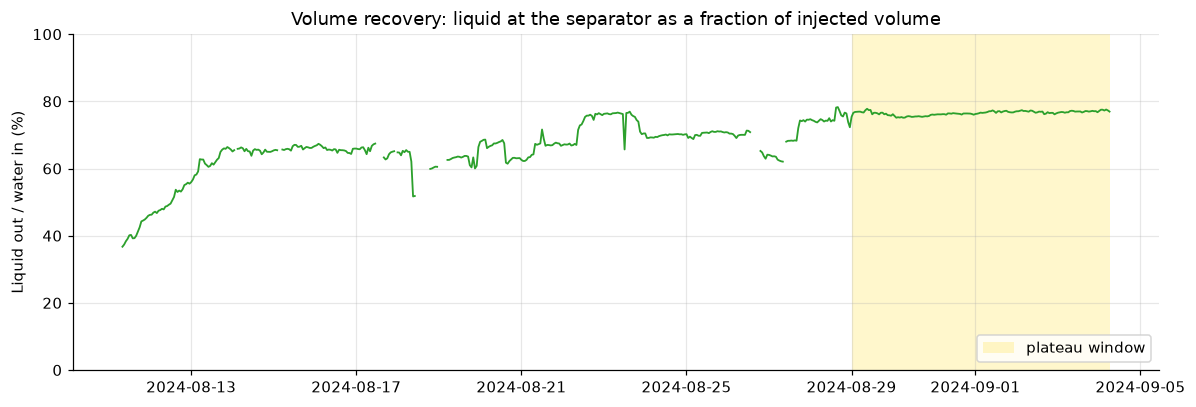

Whole steady period : 69%   (notebook 02 quotes 70%, the ratio of the two medians; this is the median of the ratio)
Plateau window      : 77%


In [5]:
hs["vol_recovery"] = hs["sep_total_corr_gpm"] / hs["inj_gpm"]

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(hs.index, hs["vol_recovery"] * 100, color="tab:green", lw=1.2)
shade_window(ax, plateau.index.min(), plateau.index.max(), label="plateau window")
ax.set_ylabel("Liquid out / water in (%)"); ax.set_ylim(0, 100)
ax.set_title("Volume recovery: liquid at the separator as a fraction of injected volume")
ax.legend(loc="lower right")
savefig(fig, "03_volume_recovery.png"); plt.show()

print(f"Whole steady period : {(steady['sep_total_corr_gpm'] / steady['inj_gpm']).median()*100:.0f}%   (notebook 02 quotes 70%, the ratio of the two medians; this is the median of the ratio)")
print(f"Plateau window      : {(plateau['sep_total_corr_gpm'] / plateau['inj_gpm']).median()*100:.0f}%")

Recovery rises from about 40% on the first day to about 77% on the plateau. It is below 100% for two reasons:
1. About a fifth of the hot water flashes to steam at the separator, which the liquid meters do not measure.
2. Some water remains in the formation or is lost to it.

Separating the two requires an estimate of the steam, calculated in the next section.

## 4. Steam fraction

Water at about 375 °F is liquid in the well because of the pressure. At the separator the pressure drops to atmospheric (the site is at 5,415 ft, so atmospheric pressure is lower than at sea level) and the water can remain liquid only below its boiling point, about 202 °F. The excess heat boils part of the water into steam.

An energy balance gives the steam fraction:

$$\text{steam fraction} = \frac{h_\text{liquid}(T_\text{well}) - h_\text{liquid}(T_\text{boil})}{h_\text{fg}}$$

where $h$ is the enthalpy (energy content, kJ/kg) of the water and $h_\text{fg}$ is the energy needed to boil 1 kg. Enthalpy values come from standard steam tables via the `iapws` library.

Separator conditions first:

In [6]:
sep = separator_conditions()          # uses elevation 5,415 ft
print(f"Air pressure at the separator : {sep['p_MPa']*1000:.1f} kPa")
print(f"Boiling point (calculated)    : {sep['T_boil_F']:.1f} °F   (report: 202.2 °F)")
print(f"Density of liquid at boiling  : {sep['rho_liquid']:.0f} kg/m³")
print(f"Energy to boil 1 kg           : {sep['h_fg']:.0f} kJ/kg")

Air pressure at the separator : 83.0 kPa
Boiling point (calculated)    : 202.1 °F   (report: 202.2 °F)
Density of liquid at boiling  : 962 kg/m³
Energy to boil 1 kg           : 2271 kJ/kg


The boiling point calculated from altitude agrees with the report to within 0.1 °F. Steam fraction for a range of well temperatures:

In [7]:
temps = np.array([300, 340, 360, 375, 380, 390])
pd.DataFrame({"well temperature (°F)": temps,
              "steam fraction (%)": (steam_fraction(temps, sep) * 100).round(1)}).set_index("well temperature (°F)")

,steam fraction (%)
well temperature (°F),
300,10.2
340,14.5
360,16.6
375,18.2
380,18.8
390,19.9


Looking up the steam tables 80,000 times would be slow, so `analysis.py` computes the table once on a 1 °F grid and `np.interp(x, grid_x, grid_y)` interpolates between grid points.

The calculated steam fraction through the test, compared with the report's 19.6%:

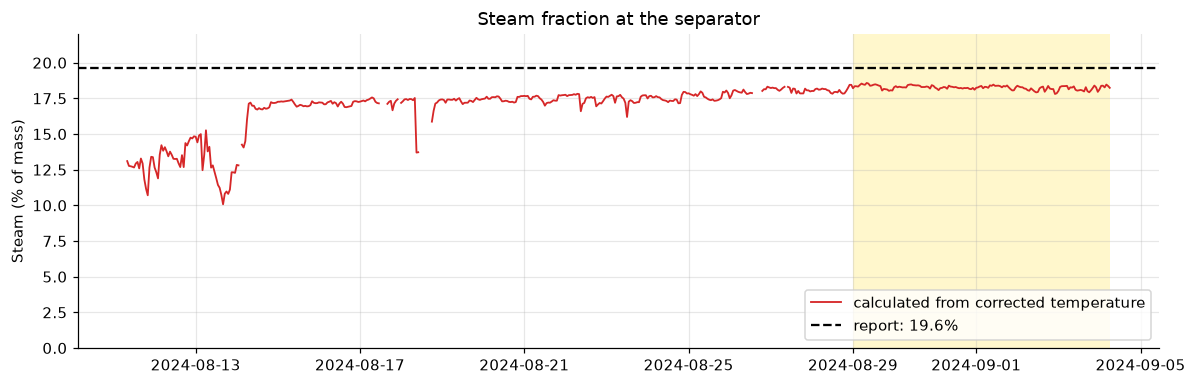

Plateau: temperature 375 °F  ->  steam 18.3%
The report's 19.6% corresponds to a well temperature of about 387 °F in this energy balance.


In [8]:
hs["steam_frac"] = mf["steam_frac"].resample("1h").median()
T_for_report = np.interp(0.196, steam_fraction(np.arange(300, 400.0), sep), np.arange(300, 400.0))

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hs.index, hs["steam_frac"] * 100, color="tab:red", lw=1.2, label="calculated from corrected temperature")
ax.axhline(19.6, color="k", ls="--", label="report: 19.6%")
shade_window(ax, plateau.index.min(), plateau.index.max())
ax.set_ylabel("Steam (% of mass)"); ax.set_ylim(0, 22)
ax.set_title("Steam fraction at the separator"); ax.legend(loc="lower right")
savefig(fig, "03_steam_fraction.png"); plt.show()

print(f"Plateau: temperature {plateau['T16B_corr_F'].median():.0f} °F  ->  steam {mf.loc[plateau.index, 'steam_frac'].median()*100:.1f}%")
print(f"The report's 19.6% corresponds to a well temperature of about {T_for_report:.0f} °F in this energy balance.")

The calculated steam fraction follows the temperature and settles at about 18%, slightly below the report's 19.6%. The report's value corresponds to a well temperature of about 387 °F in this energy balance, about 12 °F above the corrected temperature used here. That gap is of the same size as the temperature correction (+11 °F, standard deviation 4.6 °F). The effect on the results is tested in section 6.

## 5. Mass flow and efficiency

Volumes are not comparable between cold water, hot water and steam because their densities differ. The report therefore compares mass flow rates (kg/s):

- Injected mass = injected volume × density of the cold water. The injection water temperature is not in the dataset. The report describes ambient-temperature pit water, so 20 °C (68 °F) is assumed and tested in section 6.
- Produced mass = liquid at the separator (volume × density at the boiling point) plus the steam. If steam is a fraction $x$ of the total, total = liquid ÷ (1 − $x$).
- Efficiency = produced mass ÷ injected mass.

`mass_flows()` in `src/analysis.py` implements this. It was already used in section 1.

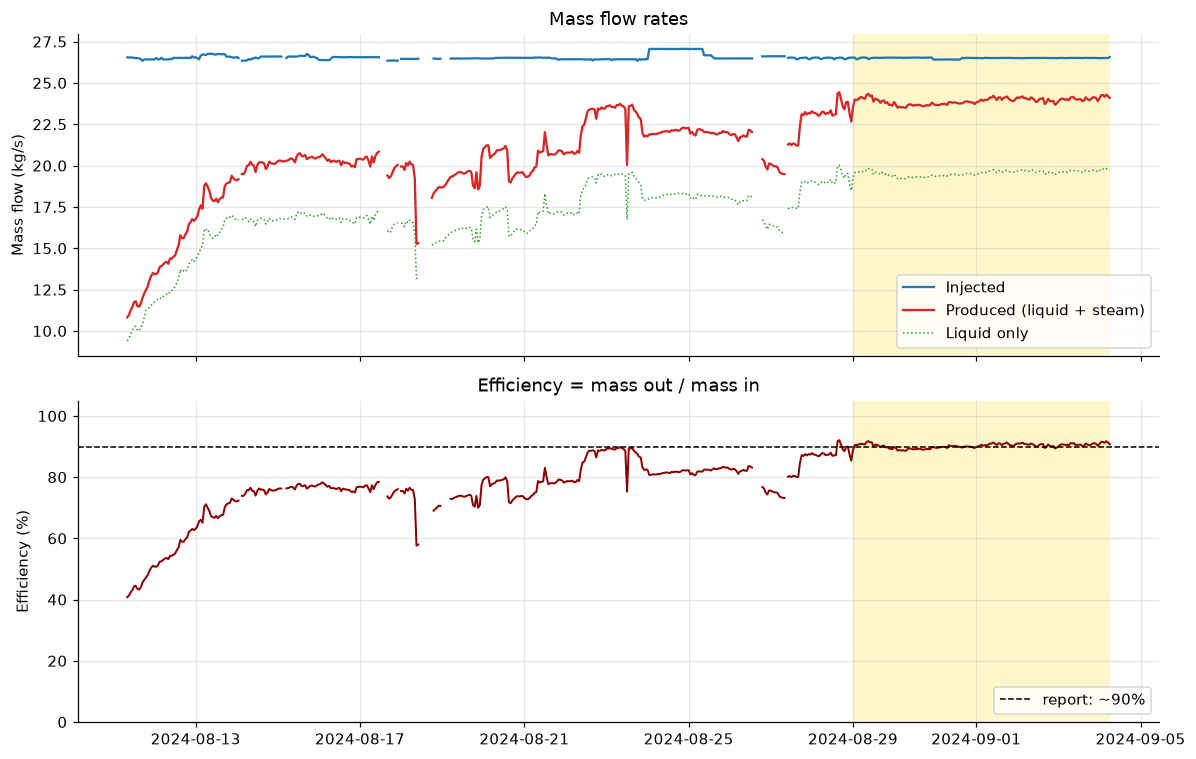

In [9]:
hm = mf.resample("1h").median()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(hm.index, hm["inj_kg_s"], color="tab:blue", label="Injected")
ax[0].plot(hm.index, hm["produced_kg_s"], color="tab:red", label="Produced (liquid + steam)")
ax[0].plot(hm.index, hm["sep_liquid_kg_s"], color="tab:green", lw=1, ls=":", label="Liquid only")
ax[0].set_ylabel("Mass flow (kg/s)"); ax[0].set_title("Mass flow rates"); ax[0].legend(loc="lower right")

ax[1].plot(hm.index, hm["efficiency"] * 100, color="darkred", lw=1.3)
ax[1].axhline(90, color="k", ls="--", lw=1, label="report: ~90%")
for a in ax:
    shade_window(a, plateau.index.min(), plateau.index.max())
ax[1].set_ylabel("Efficiency (%)"); ax[1].set_ylim(0, 105); ax[1].legend(loc="lower right")
ax[1].set_title("Efficiency = mass out / mass in")
savefig(fig, "03_mass_flow_efficiency.png"); plt.show()

In [10]:
p = mf.loc[plateau.index]
print("PLATEAU WINDOW (medians)")
print(f"  Injected mass flow : {p['inj_kg_s'].median():5.1f} kg/s   (report: ~26.5 kg/s)")
print(f"  Produced mass flow : {p['produced_kg_s'].median():5.1f} kg/s   (report figure: ~23 kg/s at the end)")
print(f"  Efficiency         : {p['efficiency'].median()*100:5.1f} %      middle 50% of readings: {p['efficiency'].quantile(.25)*100:.1f} to {p['efficiency'].quantile(.75)*100:.1f} %   (report: ~90%)")

PLATEAU WINDOW (medians)
  Injected mass flow :  26.5 kg/s   (report: ~26.5 kg/s)
  Produced mass flow :  23.9 kg/s   (report figure: ~23 kg/s at the end)
  Efficiency         :  90.3 %      middle 50% of readings: 89.7 to 90.8 %   (report: ~90%)


Efficiency on the plateau is about 90%, in agreement with the report. The injected flow of 26.5 kg/s matches the report and the produced flow of about 24 kg/s is in the range of the report's figure.

No parameter was tuned to reach 90%. The result follows from the flow calibration, the temperature correction and the steam-table calculation applied to the raw data.

The daily summary shows how the well evolved:

In [11]:
daily = pd.DataFrame({
    "injection (gpm)": steady["inj_gpm"].groupby(steady.index.date).median(),
    "inj. pressure (psi)": steady["p_inj_psi"].groupby(steady.index.date).median(),
    "liquid out (gpm)": steady["sep_total_corr_gpm"].groupby(steady.index.date).median(),
    "temperature (°F)": steady["T16B_corr_F"].groupby(steady.index.date).median(),
    "steam (%)": mf["steam_frac"].groupby(steady.index.date).median() * 100,
    "produced (kg/s)": mf["produced_kg_s"].groupby(steady.index.date).median(),
    "efficiency (%)": mf["efficiency"].groupby(steady.index.date).median() * 100,
})
daily["injectivity (gpm/100psi)"] = daily["injection (gpm)"] / daily["inj. pressure (psi)"] * 100
daily.index.name = "date"
daily.round(1)

,injection (gpm),inj. pressure (psi),liquid out (gpm),temperature (°F),steam (%),produced (kg/s),efficiency (%),injectivity (gpm/100psi)
date,,,,,,,,
2024-08-11,420.7,2752.1,169.7,324.7,12.8,11.8,44.6,15.3
2024-08-12,420.9,2815.2,207.4,331.9,13.6,14.5,54.8,15.0
2024-08-13,423.6,2865.9,263.7,320.7,12.4,18.1,67.8,14.8
2024-08-14,420.8,2852.1,275.1,362.1,16.8,20.0,75.5,14.8
2024-08-15,422.5,2899.0,278.7,365.3,17.2,20.4,76.9,14.6
2024-08-16,420.3,2914.0,276.6,365.1,17.2,20.3,76.4,14.4
2024-08-17,420.3,2952.1,277.0,366.5,17.3,20.3,76.6,14.2
2024-08-18,420.2,2916.5,267.1,366.8,17.3,19.6,74.9,14.4
2024-08-19,420.4,2930.3,264.5,367.1,17.4,19.4,73.6,14.3


Efficiency starts near 45% and climbs to about 90%, while the temperature rises from about 320 to 375 °F. This is consistent with the fracture network filling and connecting, which the report's authors expected from the earlier nine-hour test.

The rise is not monotonic. Efficiency reached about 89% on 23 Aug, fell to about 82% after the injection-rate increase on 24 Aug and the half-rate period on 26 Aug, and recovered to 90% by 29 Aug. Changes in flow disturb the system for several days, which is why results are quoted for a plateau rather than averaged over the whole test.

## 6. Sensitivity analysis

The efficiency depends on several assumptions. Each is varied in turn, the efficiency recomputed, and the change recorded.

| Assumption varied | Reason |
|---|---|
| Injection water temperature (10 to 30 °C) | Not in the dataset; 20 °C assumed |
| Calibration line through the origin instead of with an intercept | The report shows its equations only in a figure |
| Temperature offset ±4.6 °F (one standard deviation) | Spread of the manual readings |
| Raw temperature, no correction | Tests the effect of the temperature correction |
| Steam fixed at the report's 19.6% of the total | The report's value instead of the calculated one |
| Steam of 19.6% added to the liquid mass | A different reading of the report's wording |

In [12]:
cal = load_flow_calibration()
const = load_constants()
manual = load_manual_tp()
_, T_spread, _ = temperature_offset(manual)

def eff(frame, **kw):
    return mass_flows(frame, **kw)["efficiency"].median()

# Alternative calibration: best straight line forced through (0, 0)
alt = recalibrate_through_origin(plateau, const, cal)

def shifted(dT):
    f = plateau.copy(); f["T16B_corr_F"] = f["T16B_corr_F"] + dT; return f

base = eff(plateau)
scenarios = {
    "Injection water 10 °C":                     eff(plateau, T_inj_C=10),
    "Injection water 30 °C":                     eff(plateau, T_inj_C=30),
    "Calibration through the origin":            eff(alt),
    f"Temperature offset -{T_spread:.1f} °F":    eff(shifted(-T_spread)),
    f"Temperature offset +{T_spread:.1f} °F":    eff(shifted(+T_spread)),
    "Raw temperature (no correction)":           eff(plateau, T_col="T16B_F"),
    "Steam fixed at 19.6% of total (report)":    eff(plateau, steam_x=0.196),
    "Steam 19.6% added to the liquid":           eff(plateau, steam_x=0.196 / 1.196),
}
sens = pd.Series(scenarios, name="efficiency")
table = pd.DataFrame({"efficiency (%)": sens * 100, "change vs base (points)": (sens - base) * 100})
print(f"BASE CASE: {base*100:.1f}%\n")
table.round(1)

BASE CASE: 90.3%



,efficiency (%),change vs base (points)
Injection water 10 °C,90.1,-0.1
Injection water 30 °C,90.5,0.2
Calibration through the origin,92.2,1.9
Temperature offset -4.6 °F,89.7,-0.5
Temperature offset +4.6 °F,90.8,0.6
Raw temperature (no correction),88.9,-1.3
Steam fixed at 19.6% of total (report),91.8,1.5
Steam 19.6% added to the liquid,88.3,-2.0


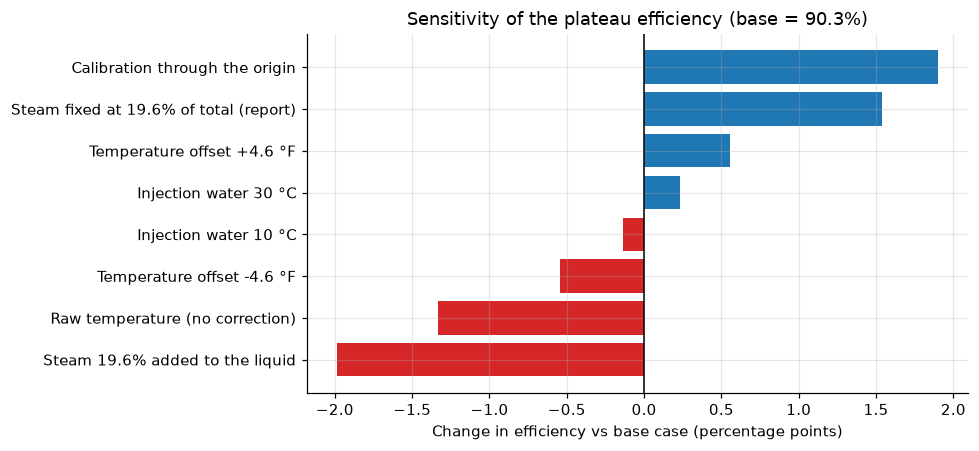

Across all scenarios the plateau efficiency ranges from 88.3% to 92.2%.
Without counting any steam at all it would be only 74%, so steam matters far more than any single choice here.


In [13]:
change = (sens - base) * 100
order = change.sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(order.index, order.values, color=["tab:red" if v < 0 else "tab:blue" for v in order.values])
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Change in efficiency vs base case (percentage points)")
ax.set_title(f"Sensitivity of the plateau efficiency (base = {base*100:.1f}%)")
savefig(fig, "03_sensitivity.png"); plt.show()

lo, hi = sens.min() * 100, sens.max() * 100
print(f"Across all scenarios the plateau efficiency ranges from {lo:.1f}% to {hi:.1f}%.")
print(f"Without counting any steam at all it would be only {eff(plateau, steam_x=0.0)*100:.0f}%, so steam matters far more than any single choice here.")

`ax.barh(labels, values)` draws horizontal bars. Sorted, they form a tornado chart in which the largest effects sit at the extremes.

- Every scenario gives an efficiency between about 88% and 92%.
- The largest effects are the calibration form (+1.9 points) and the definition of the steam fraction (about −2 to +1.5 points). All other scenarios move the result by less than 1.5 points.
- The injection water temperature changes the efficiency by only about ±0.2 points, so the 20 °C assumption does not matter for efficiency (it does for power; see notebook 04).

Result: about 90%, plausible range 88–92%.

## 7. Key results and saving

In [14]:
key = pd.Series({
    "plateau length (days)": plateau.index.normalize().nunique(),
    "injection rate (gpm)": plateau["inj_gpm"].median(),
    "injection rate (kg/s)": p["inj_kg_s"].median(),
    "injection pressure (psi)": plateau["p_inj_psi"].median(),
    "pressure trend after peak (psi/day)": p_trend["slope_per_day"],
    "injectivity (gpm/100psi)": injectivity_index(plateau).median(),
    "producer temperature, corrected (F)": plateau["T16B_corr_F"].median(),
    "steam fraction (%)": p["steam_frac"].median() * 100,
    "volume recovery, liquid only (%)": (plateau["sep_total_corr_gpm"] / plateau["inj_gpm"]).median() * 100,
    "produced mass flow (kg/s)": p["produced_kg_s"].median(),
    "efficiency, base case (%)": base * 100,
    "efficiency, lowest scenario (%)": lo,
    "efficiency, highest scenario (%)": hi,
}, name="value")

key.round(2).to_csv("../data/processed/key_results.csv", index_label="metric")
daily.round(3).to_csv("../data/processed/performance_daily.csv")
print(f"Plateau window: {plateau_start} to {plateau.index.max().date()}")
key.round(2).to_frame()

Plateau window: 2024-08-29 to 2024-09-04


,value
plateau length (days),7.00
injection rate (gpm),420.88
injection rate (kg/s),26.51
injection pressure (psi),2825.25
pressure trend after peak (psi/day),-11.07
injectivity (gpm/100psi),14.91
"producer temperature, corrected (F)",375.32
steam fraction (%),18.27
"volume recovery, liquid only (%)",76.58
produced mass flow (kg/s),23.93


## Summary

| Question | Answer |
|---|---|
| Injection pressure | ~2,825 psi on the plateau, falling ~11 psi/day (about 5% over two weeks) after the late-August peak |
| Injectivity | ~14.9 gpm per 100 psi, rising as the pressure falls |
| Volume recovery (liquid only) | ~77% on the plateau, up from ~40% on the first day |
| Steam fraction | ~18%, calculated from steam tables (report: 19.6%) |
| Mass efficiency | ~90% (plausible range 88–92%); the report gives ~90% |
| Largest uncertainties | calibration form and the definition of the steam fraction |

### Caveats
- The injection water temperature is assumed (20 °C). It has little effect on efficiency.
- Injectivity uses wellhead pressure, so only its trend is meaningful.
- The plateau is chosen by a rule (within 2% of the final efficiency); efficiency was still rising slightly within it.

Next notebook: `04_power_decline.ipynb` computes thermal power from these mass flows and tests whether it declines.